In [1]:
from pathlib import Path
import pandas as pd

import soundfile as sf

import matplotlib.pyplot as plt

import json

from tqdm import tqdm


import os

In [2]:
root_dir = Path("/home/jet/UCDavis/Gesture_Speech_Semantic_Grounding/Semantic Grounding Project/annotated_using_kipp_annotations_active_learning")

In [3]:
video_extensions = {".mp4"}

In [4]:
data = []
video_suffix_set = set()

not_processed_count = 0
for video_path in root_dir.rglob("*"):
    if video_path.suffix.lower() in video_extensions:
        # Assuming your structure is root_dir / category_folder / video.mp4
        # The parent folder name acts as the category/label
        category = video_path.parent.name
        filename = video_path.name
        relative_path = str(video_path.relative_to(root_dir))
        absolute_path = str(video_path.resolve())
    
        data.append({
            "filename": filename,
            "category": category,
            "relative_path": relative_path,
            "absolute_path": absolute_path,
            "file_size_mb": round(video_path.stat().st_size / (1024 * 1024), 2),
        })
    else:
        video_suffix_set.add(video_path)
        # print(f"{video_path} extension not processed")
        not_processed_count += 1
# print(not_processed_count)
# print(video_suffix_set)

In [5]:
video_df = pd.DataFrame(data)

In [6]:
print(f"Total videos found: {len(video_df)}")
display(video_df.head())

# find . -type f | wc -l # same result

Total videos found: 7278


,filename,category,relative_path,absolute_path,file_size_mb
0,1-2_seg_522.47-522.87.mp4,Emblem.Big,Emblem.Big/1-2_seg_522.47-522.87.mp4,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.03
1,1-4_seg_384.80-385.12.mp4,Emblem.Big,Emblem.Big/1-4_seg_384.80-385.12.mp4,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.03
2,1-2_seg_328.27-328.62.mp4,Emblem.Big,Emblem.Big/1-2_seg_328.27-328.62.mp4,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.03
3,1-2_seg_95.04-95.64.mp4,Emblem.Big,Emblem.Big/1-2_seg_95.04-95.64.mp4,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.04
4,1-2_seg_510.97-511.42.mp4,Emblem.Big,Emblem.Big/1-2_seg_510.97-511.42.mp4,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.04


In [7]:
video_df.to_csv("video_dataset_index.csv", index=False)

In [8]:
category_occurences = video_df['category'].value_counts()
print(category_occurences[1:])

category
Meta.Spread-Apart      210
Meta.Offer-Out         160
Meta.Cup               151
Meta.Chop              148
Deictic.Space-Right    141
                      ... 
Emblem.Hand-Rub          1
H                        1
AM                       1
E                        1
I                        1
Name: count, Length: 165, dtype: int64


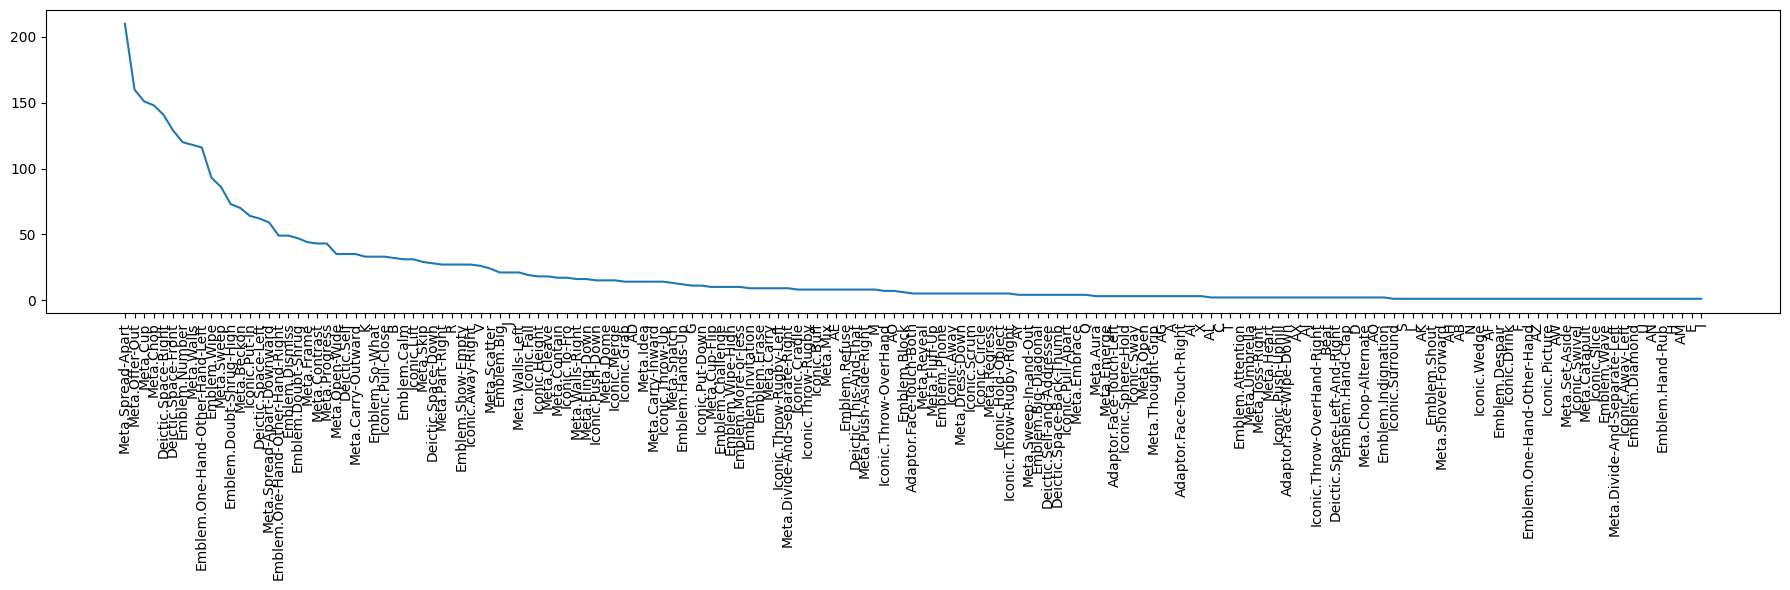

In [9]:
plt.figure(figsize=(18, 6))
plt.plot(category_occurences[1:])
# Source - https://stackoverflow.com/a/37708190
# Posted by scottlittle
# Retrieved 2026-10-29, License - CC BY-SA 3.0

plt.xticks(rotation=90)
plt.tight_layout() 
plt.show()

In [10]:
root_dir = Path("/home/jet/UCDavis/Gesture_Speech_Semantic_Grounding/Semantic Grounding Project/audio/segments")

In [11]:
audio_extensions = {".wav"}

In [12]:
# 1. Does the path actually exist on your system?
print("Does path exist?", root_dir.exists())

# 2. Is Python treating it as a directory?
print("Is it a directory?", root_dir.is_dir())

# 3. What is the exact full path Jupyter is looking at?
print("Resolved absolute path:", root_dir.resolve())
print(root_dir.rglob("*"))
# for audio_path in root_dir.rglob("*"):
#     print("hi: ", audio_path)

Does path exist? True
Is it a directory? True
Resolved absolute path: /home/jet/UCDavis/Gesture_Speech_Semantic_Grounding/Semantic Grounding Project/audio/segments
<generator object Path.rglob at 0x73c0e7027bc0>


In [13]:
audio_data = []
audio_suffix_set = set()



for audio_path in root_dir.rglob("*"):

 
    if audio_path.suffix.lower() in audio_extensions:

        # Assuming your structure is root_dir / category_folder / video.mp4
        # The parent folder name acts as the category/label
        category = audio_path.parent.name
        filename = audio_path.name
        relative_path = str(audio_path.relative_to(root_dir))
        absolute_path = str(audio_path.resolve())
        
        try:
            # sf.info() is super fast because it only reads the file header
            duration_sec = round(sf.info(str(audio_path)).duration, 2)
        except Exception as e:
            # Fallback in case a file is corrupted or unsupported
            print(f"Could not read duration for {filename}: {e}")
            duration_sec = 0.0
            
        audio_data.append({
            "filename": filename,
            "category": category,
            "relative_path": relative_path,
            "absolute_path": absolute_path,
            "file_size_mb": round(audio_path.stat().st_size / (1024 * 1024), 2),
            "duration_sec": duration_sec,
            
        })
#     else:
#         audio_suffix_set.add(audio_path)
#         print(f"{audio_path} extension not processed")
    
# print(audio_suffix_set)

In [14]:
audio_df = pd.DataFrame(audio_data)

In [15]:
print(f"Total audio files found: {len(audio_df)}")
display(audio_df.head())

# find . -type f | wc -l # same result

Total audio files found: 7157


,filename,category,relative_path,absolute_path,file_size_mb,duration_sec
0,2-3_seg_308.34-308.66.wav,segments,2-3_seg_308.34-308.66.wav,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.17,1.0
1,4-6_seg_407.66-408.01.wav,segments,4-6_seg_407.66-408.01.wav,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.34,2.0
2,3-2_seg_700.42-700.82.wav,segments,3-2_seg_700.42-700.82.wav,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.17,1.0
3,2-2_seg_141.68-142.04.wav,segments,2-2_seg_141.68-142.04.wav,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.34,2.0
4,4-2_seg_562.67-563.07.wav,segments,4-2_seg_562.67-563.07.wav,/home/jet/UCDavis/Gesture_Speech_Semantic_Grou...,0.34,2.0


In [16]:
audio_df.to_csv("audio_dataset_index.csv", index=False)

In [17]:
audio_category_occurences = audio_df['duration_sec'].value_counts()
print(audio_category_occurences)

duration_sec
1.0    3859
2.0    3298
Name: count, dtype: int64


/tmp/ipykernel_586350/1603736629.py:2: FutureWarning: The behavior of obj[i:j] with a float-dtype index is deprecated. In a future version, this will be treated as positional instead of label-based. For label-based slicing, use obj.loc[i:j] instead
  plt.plot(audio_category_occurences[1:])


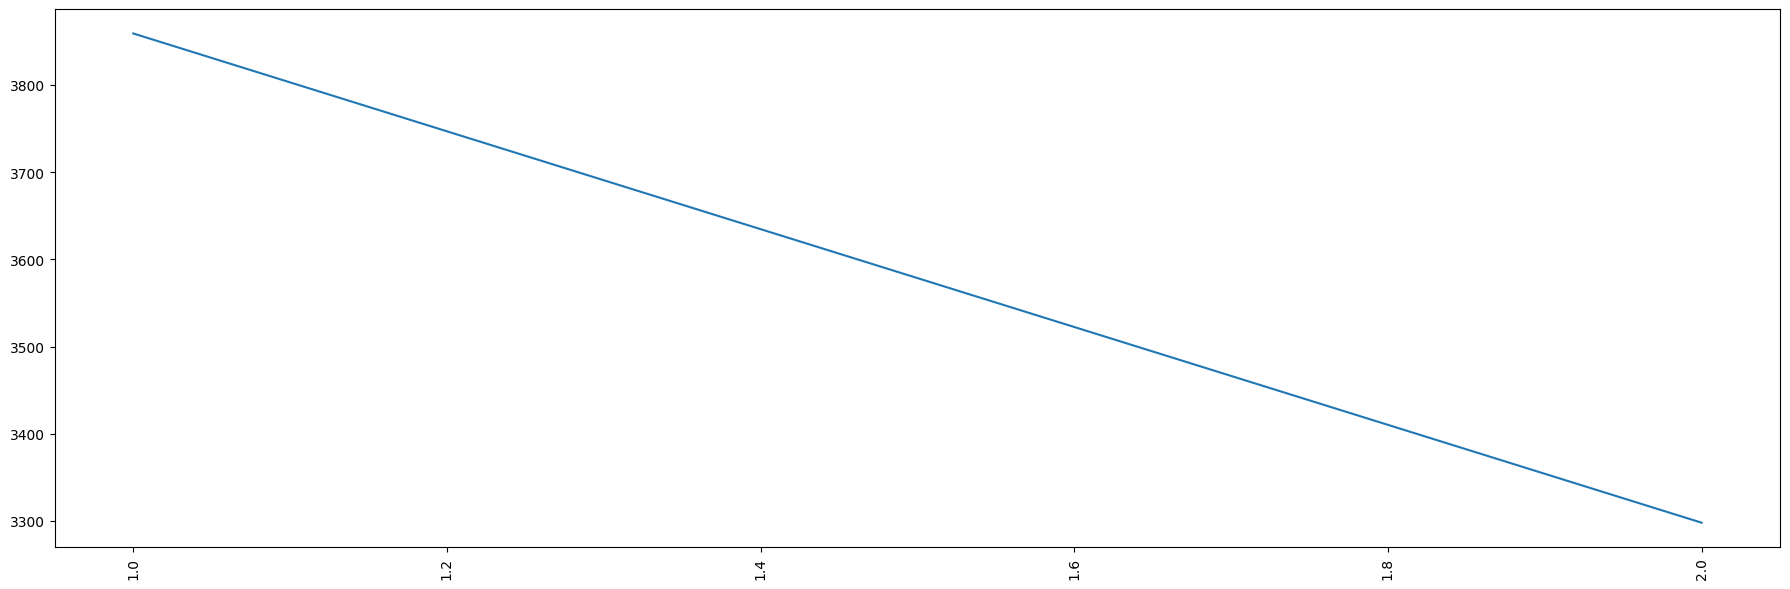

In [18]:
plt.figure(figsize=(18, 6))
plt.plot(audio_category_occurences[1:])
# Source - https://stackoverflow.com/a/37708190
# Posted by scottlittle
# Retrieved 2026-10-29, License - CC BY-SA 3.0

plt.xticks(rotation=90)
plt.tight_layout() 
plt.show()

In [19]:
# i am noticing that the audio transcription model is struggling a bit from the segments? and also from accent? it feels like a 80% correct transcription

In [20]:
import regex as re

remove_extension_regex = r"(.*)[.](.*)"

def remove_extension(filename):
    # print(filename)
    matches = re.search(remove_extension_regex, filename) 
    # print(matches.group(1))
    return matches.group(1)

In [21]:
with open('file_to_transcription.json', 'r') as f:
    file_to_transcription = json.load(f)

In [22]:
len(file_to_transcription)
# file_to_transcription[0]['1-1_seg_102.17-102.62.wav']

file_to_transcription_dict = {}
for item in file_to_transcription:
    # print(list(item.keys())[0])
    filename_no_extension = remove_extension(list(item.keys())[0])
    # print(filename_no_extension)
    if filename_no_extension not in file_to_transcription_dict:
        file_to_transcription_dict[filename_no_extension] = list(item.values())[0]

print(len(file_to_transcription_dict))

7157


# Creating connection from audio to text

In [23]:
#hmmm there is a mismatch
print(audio_df.shape)
print(video_df.shape)

(7157, 6)
(7278, 5)


In [24]:
# print(list(video_df[:]["absolute_path"]))

In [25]:
video_and_audio_filename_to_text = {}

audio_filename_list = []

remove_extension_regex = r"(.*)[.](.*)"

for audio_filename in audio_df["filename"]:
    audio_filename_no_extension = remove_extension(audio_filename)
    audio_filename_list.append(audio_filename_no_extension)

missing_temp = 0
for video_filename in video_df["filename"]:
    # print(video_filename)
    video_filename_no_extension = remove_extension(video_filename)
    
    if video_filename_no_extension not in video_and_audio_filename_to_text:
        video_and_audio_filename_to_text[video_filename_no_extension] = ""
    else:
        print(f"video_filename_no_ext {video_filename_no_extension} already in video and audio filename to text list")
        
    if video_filename_no_extension in audio_filename_list:
        transcription_text = file_to_transcription_dict[video_filename_no_extension]
        # print(transcription_text)
        video_and_audio_filename_to_text[video_filename_no_extension] = transcription_text
    else:
        missing_temp += 1
        # print(f"video_filename_no_ext {video_filename_no_extension} not in audio_filename_list")
print(missing_temp)

121


In [26]:
# print(len(video_and_audio_filename_to_text))
# video_and_audio_filename_to_text

In [27]:
#converting video_and_audio_filename_to_text to a json array with shorter name
video_to_transcript = [{key: value} for key, value in video_and_audio_filename_to_text.items()]
sorted_dict = sorted(video_to_transcript, key=lambda d: list(d.keys())[0])
print(len(sorted_dict))

# with open("video_to_transcript.json", "w") as f:
#     json.dump(sorted_dict, f, indent=4)
    

7278


In [28]:
video_absolute_paths = list(video_df[:]["absolute_path"])

gesture_category_regex = r"(annotated_using_kipp_annotations_active_learning)\/(.*)\/(.*)"
def gesture_category_finder(file_path):
    matches = re.search(gesture_category_regex, file_path)
    # print(matches.group(3), matches.group(2))
    
    return {remove_extension(matches.group(3)): matches.group(2)}

gesture_category_dict = {}
for abs_path in video_absolute_paths:
    gesture_category = gesture_category_finder(abs_path)
    gesture_category_dict.update(gesture_category)

filename_to_gesture_category = gesture_category_dict
# print(filename_to_gesture_category)
if '1-4_seg_384.80-385.12' in filename_to_gesture_category:
    print("hi")

hi


In [29]:

filename_category_transcription = []
for item in sorted_dict:
    filename_no_ext, transcription = list(item.items())[0]
    # print(filename_no_ext, ": ", transcription)
    if filename_no_ext in filename_to_gesture_category:
        # print("hi")
        temp_dict = {"filename": filename_no_ext,
                     "category": filename_to_gesture_category[filename_no_ext],
                     "transcription": transcription}
        filename_category_transcription.append(temp_dict)

print(len(filename_category_transcription))

7278


In [30]:
with open("filename_category_transcription.json", "w") as f:
    json.dump(filename_category_transcription, f, indent=4)

In [31]:
# for histogram we want
# x axis category, then bag of words, where each word's frequency is counted
# so transcript needs to be a list of tuple of (word, count)
from collections import Counter

def create_word_list(transcription):
    # transcription.split()
    split = transcription.split()

    word_list = []
    for word in split:
        no_punc = re.findall(r'\b\w+\b', word.lower())
        if no_punc:
            word_list.append(no_punc[0])
    # print(word_list)
    return word_list
    
category_to_transcription = {}
for item in filename_category_transcription:
    # print(item["category"])
    category = item["category"]
    transcription = item["transcription"]
    word_list = create_word_list(transcription)
    if category not in category_to_transcription:
        category_to_transcription[category] = []
    if category in category_to_transcription:
        category_to_transcription[category] += word_list

category_to_bow = {}
for category, transcription_list in category_to_transcription.items():
    # print(transcription_list)
    word_counts = Counter(transcription_list)
    if len(word_counts) == 0:
        print(category, " - ", word_counts, " - ", transcription_list)
    sorted_word_counts = sorted(word_counts.items(), 
        key=lambda item: item[1], 
        reverse=True)
    category_to_bow[category] = sorted_word_counts
    
category_to_bow = {
    cat: category_to_bow[cat] 
    for cat in sorted(category_to_bow.keys())
}
# print(category_to_bow["Emblem.Number"])
print(len(category_to_bow))

# print(category_to_bow)

Meta.Shovel-Forward  -  Counter()  -  []
166


# Histogram Plot of Video to Transcript Text

In [36]:
def create_histogram(target_category):
    output_dir = "./Gesture_Category_to_Word_Frequencey_plots"
    os.makedirs(output_dir, exist_ok=True)
    
    word_counts_data = category_to_bow.get(target_category, [])
    
    # categories with no words
    if not word_counts_data:
        print(f"rendering empty plot for {target_category} (No words found)")
        plt.figure(figsize=(8, 5))
        plt.text(0.5, 0.5, 'No Transcriptions / Words Found', 
                 horizontalalignment='center', verticalalignment='center', fontsize=14, color='gray')
        plt.title(f"{target_category}'s Word Frequency Distribution (0 unique words)")
        plt.axis('off')
        
        plt_file_name = f"{target_category}_word_frequency_plot.png"
        plt.savefig(os.path.join(output_dir, plt_file_name), dpi=300, bbox_inches='tight')
        plt.close()
        return

    category_word_count = dict(word_counts_data).items()
    words, counts = zip(*category_word_count)
    
    num_words = len(words)
    dynamic_width = min(210, max(8, num_words * 0.4))
    
    plt.figure(figsize=(dynamic_width, 5))
    plt.bar(words, counts, color='teal')
    plt.xlabel("Words in Transcriptions")
    plt.ylabel("Frequency")
    plt.title(f"{target_category}'s Word Frequency Distribution ({num_words} unique words)")
    plt.xticks(rotation=90, ha='right')
    plt.tight_layout()

    plt_file_name = f"{target_category}_word_frequency_plot.png"
    plt.savefig(os.path.join(output_dir, plt_file_name), dpi=300, bbox_inches='tight')

    # plt.show()
    plt.close()

In [37]:
# count = 1
# for category, bow in tqdm(category_to_bow.items()):
#     # print(f"{count}: {category}")
#     # count += 1
#     if category:
#         create_histogram(category)
#     else:
#         print(f"Error: {category}")

In [38]:
create_histogram("Unknown")